<a href="https://colab.research.google.com/github/taseabolt/CS620Project/blob/main/Araojo_Seabolt_Partain_Pan_CS620_DataProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Abstract:


**Group members:**

*  Izzy Araojo, iarao001@odu.edu, https://araojo-izzy.github.io/
*  Tara Seabolt, tseab002@odu.edu, https://https://taseabolt.github.io/
*  Justin Partain, jpart003@odu.edu https://justintimedev.github.io/
*  Andy Pan, apan009@odu.edu, https://thepandoi.github.io/


**Raw Data Source:** https://catalog.data.gov/dataset/lottery-mega-millions-winning-numbers-beginning-2002

**Short Description:** A dataset of winning numbers for Mega Millions for 2002 to 2020 in New York.

**End Goal with Dataset:** Build a prediction model to forecast future winning numbers.

**Seconday Dataset(s)**: N/A

**Project Plan/Gannt Chart:** 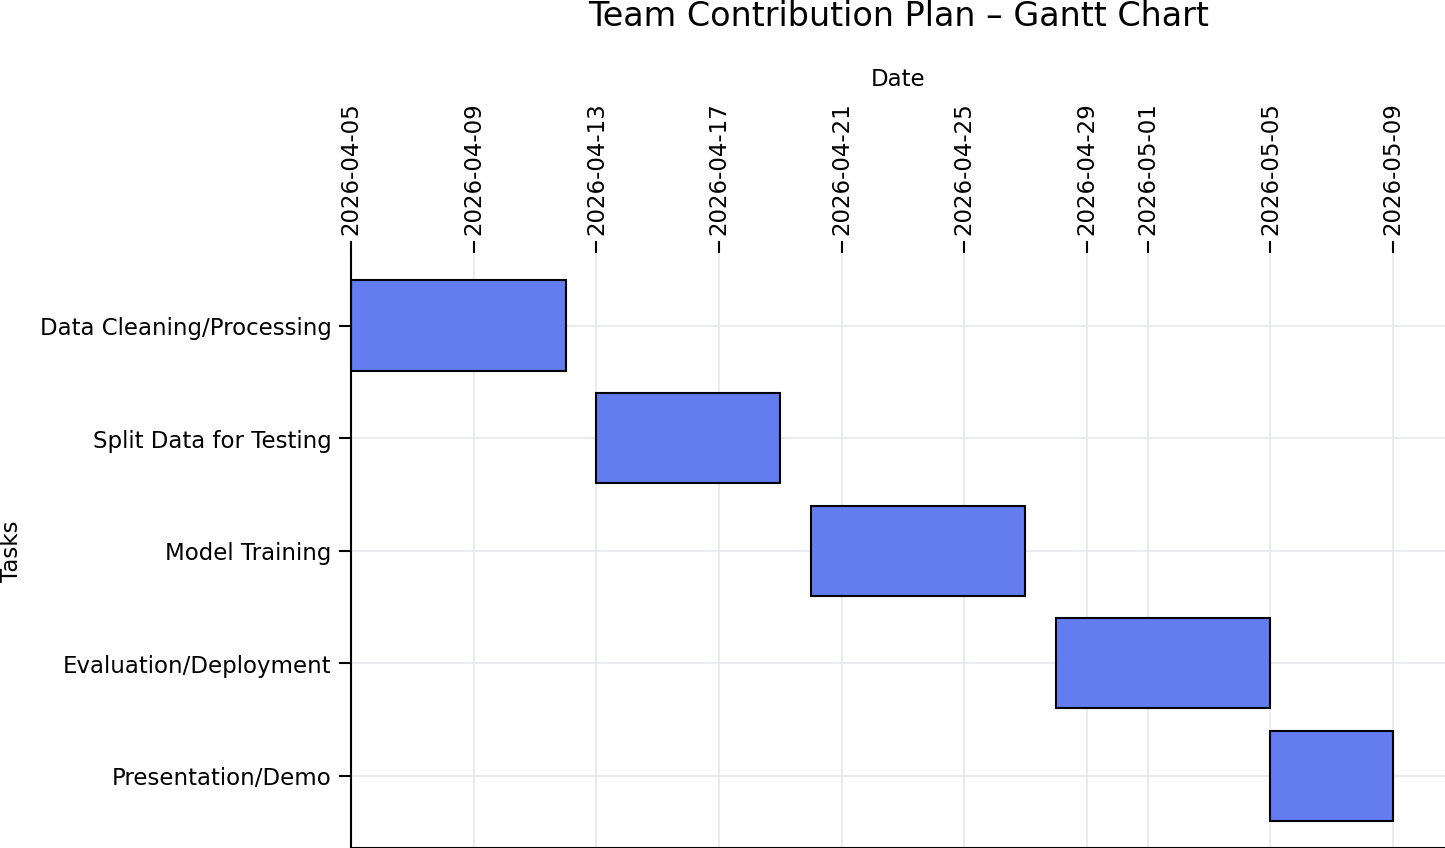 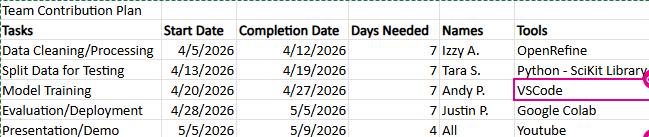

# Progress Check 1:


**Design Decisions:**

* **Target Audience:** Those who are interested in playing the lottery
* **Tools/Technologies:** OpenRefine for data cleaning/organization, Python and scikit-learn library to split the data for the model's testing, training, and validation, Colab for collaboration, coding, and final deployment, VSCode for Model training
* **Data Models:** Prediction model to use historical data and machine learning algorithms to predict future outcomes
* **Overall Design & Core Features:** The user will be able to provide input as select numbers in a command prompt. The model will then inform the user their odds of winning with the selected numbers.
* **User Satisfaction:** Since our targeted audience are those who wish to play the lottery, we can also assume that they want to win the lottery. By drawing data from past winning numbers, we can give them statistics that can increase their odds of winning
* **Code Snippets:** See below

**Current Status:**
* **Implementation Status:** The data is now cleaned and organized and undergone a 70-15-15 split for training, testing, and validation sets to utilize during model building and training.
* **Remaining Steps:** We will build the prediction model, which involves model training, testing and validation prior to final deployment. After the model is complete, the presentation and demo will be done to finalize the project.

In [ ]:
# Data split code
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the data
df = pd.read_csv("https://raw.githubusercontent.com/taseabolt/CS620Project/main/2.0%20CLEANED-Lottery-Mega-Millions-Winning-Numbers-Beginning-2002.csv")
print("Original loaded data file:", '\n', df.head(), '\n')

# Convert dates and sort chronologically
df["Draw Date"] = pd.to_datetime(df["Draw Date"], format="%m/%d/%y")
df = df.sort_values("Draw Date").reset_index(drop=True)
print("Data file w/converted dates & ascending order:", '\n', df.head(), '\n')

# Split winning numbers into separate columns
balls = df["Winning Numbers"].str.split(expand=True).astype(int)
balls.columns = ["Num1", "Num2", "Num3", "Num4", "Num5"]
df = df.drop(columns=["Winning Numbers"])
df = pd.concat([df, balls], axis=1)
print("Data file w/winning numbers in separate columns:", '\n', df.head(), '\n')

# Split 15% val, 15% test, 70% train
train_val, test = train_test_split(df, test_size=0.15, shuffle=False)
train, val = train_test_split(train_val, test_size=0.15, shuffle=False)
print(f"Val:   {len(val)} rows")
print(f"Test:  {len(test)} rows")
print(f"Train: {len(train)} rows")

# Save split data files
val.to_csv("lotteryval.csv",     index=False)
test.to_csv("lotterytest.csv",   index=False)
train.to_csv("lotterytrain.csv", index=False)

print("Data split completed.")

# Progress Check 2:

**Design Decisions:**

* **Target Audience:** Those who are interested in playing the lottery
* **Tools/Technologies:** OpenRefine for data cleaning/organization, Python and scikit-learn library to split the data for the model's testing, training, and validation, Colab for collaboration, coding, and final deployment, VSCode for Model training
* **Data Models:** Prediction model to use historical data and machine learning algorithms to predict future outcomes
* **Overall Design & Core Features:** The user will be able to provide input as select numbers in a command prompt. The model will then inform the user their odds of winning with the selected numbers.
* **User Satisfaction:** Since our targeted audience are those who wish to play the lottery, we can also assume that they want to win the lottery. By drawing data from past winning numbers, we can give them statistics that can increase their odds of winning
* **Code Snippets:** See below

**Current Status:**
* **Implementation Status:** The data is now cleaned and organized and undergone a 70-15-15 split for training, testing, and validation sets to utilize during model building and training. We went with RandomForestClassifier as our prediction model and tested it for performance consistency with Out-of-Bag and Validation accuracies.
* **Remaining Steps:** The presentation and demo will be done to finalize the project.

In [ ]:
# code for the prediction model
import pandas as pd
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the split files, drop rows missing data, & drop the data column
train_df = pd.read_csv("lotterytrain.csv").dropna(subset=["Multiplier"]).drop(columns="Draw Date")
test_df  = pd.read_csv("lotterytest.csv").dropna(subset=["Multiplier"]).drop(columns="Draw Date")
val_df   = pd.read_csv("lotteryval.csv").dropna(subset=["Multiplier"]).drop(columns="Draw Date")

# Splitting datasets into x and y
x_train = train_df.drop(columns="Multiplier")
y_train = train_df["Multiplier"]
x_test  = test_df.drop(columns="Multiplier")
y_test  = test_df["Multiplier"]
x_val   = val_df.drop(columns="Multiplier")
y_val   = val_df["Multiplier"]

# Cross-validated evaluation on the training set
folds = KFold(n_splits=5, shuffle=True, random_state=42)
classifier = RandomForestClassifier(n_estimators=100, random_state=42, oob_score=True)
crossval_scores = cross_val_score(classifier, x_train, y_train, cv=folds, scoring="accuracy")
print(f"Cross Validation accuracy per fold: {crossval_scores}")
print(f"Cross Validation mean accuracy:     {crossval_scores.mean():.4f}")

# Fit model and evaluation on non-included data sets
classifier.fit(x_train, y_train)
print(f"Out-of-bag accuracy:  {classifier.oob_score_:.4f}")
print(f"Validation accuracy:  {accuracy_score(y_val,  classifier.predict(x_val)):.4f}")
print(f"Test accuracy:        {accuracy_score(y_test, classifier.predict(x_test)):.4f}")

# **CS620 Data Science Project Final Report:**

## Predicting Mega Millions Outcomes Using Machine Learning

### A Comparative Analysis of Probabilistic and Deep Learning Models

| Name | Email | Portfolio |
|---------|-----|----------|
| Izzy Araojo   |   iarao001@odu.edu |   araojo-izzy.github.io |
| Tara Seabolt   |  tseab002@odu.edu  |   taseabolt.github.io |
| Justin Partain  | jpart003@odu.edu  |  justintimedev.github.io |
| Andy Pan     |    apan009@odu.edu   |   thepandoi.github.io |



### Abstract

Lottery number prediction represents one of the most challenging problems in applied machine learning, primarily because lottery draws are designed to be statistically independent and uniformly random. This project investigates whether historical Mega Millions draw data can yield any predictive signal when subjected to a suite of machine learning models ranging from simple probabilistic baselines to sophisticated deep learning architectures.

Using a dataset of Mega Millions winning numbers spanning 2002 to 2020 sourced from the New York State open data catalog, the team built and evaluated six models: a Random Baseline, a Frequency Analysis classifier, a Logistic Regression model, a first-order Markov Chain, a Long Short-Term Memory (LSTM) neural network, and a Random Forest ensemble. The dataset was split 70-15-15 into training, validation, and test partitions, and each model was evaluated on classification accuracy and a per-class F1 score against the lottery Multiplier field.

Results confirm the theoretical expectation: all models perform near or at the level of a naive frequency baseline, and no model demonstrated statistically meaningful predictive power over random chance. The project concludes with a discussion of why this outcome is expected, how the work serves as a valid academic exercise in applied machine learning methodology, and directions for future extensions including feature engineering, ensemble stacking, and analysis of non-random sub-patterns in draw sequences.

# Youtube Presentation:

[Youtube Presentation Link](https://youtu.be/YOyF-JpDGAU)

# Table of Contents:

1. [Introduction and Problem Statement](#Introduction-and-Problem-Statement)

    1.1 [Background](#Background)

    1.2 [Problem Statement](#Problem-Statement)

    1.3 [Target Audience](#Target-Audience)
2. [Dataset](#Dataset)

    2.1 [Data Source](#Data-Source)

    2.2 [Data Cleaning and Preprocessing](#Data-Cleaning-and-Preprocessing)

    2.3 [Dataset Partitioning](#Dataset-Partitioning)
3. [Design and Implementation](#design-and-implementation)

    3.1 [System Architecture Overview](#system-architecture-overview)

    3.2 [Model Selection Rationale](#model-selection-rationale)

    3.2.1 [Random Baseline](#random-Baseline)

    3.2.2 [Frequency Analysis](#Frequency-Analysis)

    3.2.3 [Logistic Regression](#Logistic-Regression)

    3.2.4 [Markov Chain](#Markov-Chain)

    3.2.5 [LSTM Neural Network](#LSTM-Neural-Network)

    3.2.6 [Random Forest](#Random-Forest)

    3.3 [Tools and Technologies](#Tools-and-Technologies)

    3.4 [User Interface](#User-Interface)
4. [Results and Evaluation](#Results-and-Evaluation)

    4.1 [Performance Metrics](#Performance-Metrics)

    4.2 [Model Performance Summary](#Model-Performance-Summary)

    4.3 [Discussion of Results](#Discussion-of-Results)

    4.4 [Evaluation Strategy](#Evaluation-Strategy)
5. [Challenges](#Challenges)

    5.1 [Fundamental Predictability Problem](#Fundamental-Predictability-Problem)

    5.2 [Class Imbalance](#Class-Imbalance)

    5.3 [LSTM Sequence Construction](#LSTM-Sequence-Construction)

    5.4 [Colab Environment Constraints](#Colab-Environment-Constraints)
6. [Conclusions and Future Work](#Conclusions-and-Future-Work)

    6.1 [Conclusions](#Conclusions)

    6.2 [Future Work](#Future-Work)
7. [References](#References)

# 1 Introduction and Problem Statement


## 1.1 Background

The Mega Millions lottery is one of the largest multi-state lottery games in the United States. Each draw selects five white balls from a pool of 1 through 70, plus one gold Mega Ball from 1 through 25. An optional Megaplier multiplier, ranging from 2x to 5x, is also drawn and applied to non-jackpot prizes. Since 2002, the New York State Gaming Commission has maintained public records of every draw, creating a structured historical dataset accessible through the federal open data catalog.

While it is mathematically established that individual lottery draws are statistically independent events governed by uniform probability distributions, the application of machine learning to this domain presents a valuable academic exercise. Such an exercise tests whether learning algorithms can overfit to noise, reveals the importance of baseline comparisons, and provides hands-on experience with a complete data science pipeline from raw data ingestion through model evaluation.

## 1.2 Problem Statement

This project addresses the following central question: Can machine learning models trained on historical Mega Millions draw records produce predictions of the Multiplier value that are statistically superior to random guessing? The Multiplier field was selected as the prediction target because it is a discrete categorical variable with a small, well-defined label set (2, 3, 4, 5, and 10), making it amenable to multi-class classification.
The specific objectives of this project are:
*   Clean and organize raw lottery draw data into a machine-learning-ready format.
*   Implement and evaluate five models of varying complexity.
*   Establish rigorous baseline comparisons to contextualize model accuracy.
*   Deliver an interactive prediction interface for end users.
*   Draw conclusions about the predictability of lottery outcomes from historical data.

## 1.3 Target Audience

The primary audience for this project is lottery enthusiasts who wish to understand their statistical odds in greater depth before selecting numbers. By presenting model-driven probability estimates alongside transparent accuracy metrics, the system provides users with informed context rather than false certainty. A secondary audience consists of data science students and practitioners who may use this project as a reference implementation of a classification pipeline applied to a challenging, low-signal domain.

# 2 Dataset

## 2.1 Data Source

The dataset used in this project is the Lottery Mega Millions Winning Numbers (Beginning 2002) dataset, published by the New York State Gaming Commission and hosted on the U.S. federal open data catalog at data.gov. The dataset contains one record per draw and includes the draw date, the five winning white ball numbers, the Mega Ball number, and the Multiplier value.

The key attributes of the raw dataset are summarized below:

| Column | Type | Description |
|---------|-----|----------|
| Draw Date | Date | Date of the lottery draw (MM/DD/YYYY) |
| Winning Numbers | String | Five space-separated integers (1–70) |
| Mega Ball | Integer | Single integer (1–25) |
| Multiplier | Integer | Optional multiplier: 2, 3, 4, 5, or 10 |

## 2.2 Data Cleaning and Preprocessing

Raw data was loaded into OpenRefine, which served as the primary tool for inspection and cleaning. Several preprocessing steps were applied before the dataset was exported for model training.
*   Rows with missing Multiplier values were removed, as the Multiplier is the prediction target. Missing values in this field occur in earlier draws when the Multiplier game was not yet offered.
*   The Draw Date column was dropped prior to model training. While temporal ordering was used during the train/validation/test split, the raw date string carries no direct numerical signal for predicting the Multiplier.
*   Winning Numbers were retained as individual integer features after splitting the space-delimited string into five separate columns (Ball_1 through Ball_5).
*   No normalization was required for tree-based models, but StandardScaler was applied to features used by the Logistic Regression model.

## 2.3 Dataset Partitioning

The cleaned dataset was partitioned using a 70-15-15 split into training, validation, and test sets, respectively. The split was performed in chronological order to prevent data leakage, ensuring that no future draw information was available to the model during training. The training set was used to fit all models, the validation set was used to monitor generalization and for potential hyperparameter tuning, and the test set was held out exclusively for final performance reporting.

| Split | Proportion | Purpose |
|---------|-----|----------|
| Training | 70% | Model fitting |
| Validation | 15% | Tuning & monitoring |
| Test | 15% | Final evaluation |

# 3 Design and Implementation

## 3.1 System Architecture Overview

The overall system is composed of four logical layers: data ingestion and cleaning, feature engineering, model training and evaluation, and the user-facing prediction interface. Each layer is implemented in Python and executed within a Google Colab environment, which provides collaborative notebooks, free GPU access for deep learning, and a shareable deployment target.


| Layer | Tools and Responsibilities |
|---------|-----|
| Data Ingestion | OpenRefine: data cleaning, deduplication, missing value removal, column parsing |
| Feature Engineering | Pandas: column splitting, type casting, chronological train/val/test split |
| Model Training | scikit-learn (LR, RF, baselines), TensorFlow/Keras (LSTM), custom Python (Markov)
| Evaluation| scikit-learn metrics: accuracy, classification report, confusion matrix |
| User Interface | Command-line prompt accepting user number selections; model returns win probability |



## 3.2 Model Selection Rationale

Five models were selected to span a wide range of complexity and theoretical assumptions. Each model represents a distinct approach to the prediction problem, enabling meaningful comparison across both simple heuristics and sophisticated sequence models.

## 3.2.1 Random Baseline

The random baseline uniformly samples a prediction from the set of known Multiplier classes for each test instance. It makes no use of training data and serves solely as the lowest possible performance floor. Any model that fails to outperform random guessing is providing no value whatsoever. For a uniform distribution over five classes (2, 3, 4, 5, 10), the expected accuracy is approximately 20%.

## 3.2.2 Frequency Analysis

The frequency analysis model always predicts the most commonly occurring Multiplier value observed in the training set. Because Multiplier probabilities are not uniform in practice (e.g., the 2x Multiplier appears far more frequently than 10x), this baseline typically outperforms the random baseline. It represents the expected accuracy of a naïve, zero-computation classifier and is a critical reference point: if a more complex model cannot beat this threshold, it has learned nothing meaningful.

## 3.2.3 Logistic Regression
Logistic Regression is a discriminative linear classifier that models the probability of each class as a softmax function of a linear combination of input features. Features were standardized via StandardScaler prior to fitting. The multinomial solver (lbfgs) was used given the multi-class nature of the target variable. Logistic Regression was selected because it is interpretable, fast to train, and serves as the standard linear classification baseline in machine learning benchmarking.

## 3.2.4 Markov Chain

The first-order Markov Chain models the lottery draw sequence as a stateful process, where the probability of the next Multiplier depends solely on the current Multiplier value. A transition probability matrix is constructed from the training sequence, and prediction is made by selecting the highest-probability next state. If a previously unseen state is encountered, the model falls back to the most frequent class. The Markov Chain is conceptually well-suited to sequence data and is a reasonable hypothesis to test, even if lottery draws are theoretically memoryless.

## 3.2.5 LSTM Neural Network

The Long Short-Term Memory network is a recurrent neural architecture specifically designed to capture long-range dependencies in sequential data. The implementation uses a sliding window of the previous 10 Multiplier values to predict the next value. The architecture consists of two stacked LSTM layers (64 and 32 units respectively) with dropout regularization (rate = 0.2) between layers, followed by a Dense softmax output layer. The model was trained for 30 epochs using the Adam optimizer and categorical cross-entropy loss. The LSTM represents the most computationally intensive hypothesis: that there exist long-range temporal patterns in the Multiplier sequence that a recurrent model can detect.

## 3.2.6 Random Forest

The Random Forest is an ensemble learning method that constructs a large number of decision trees during training and outputs the class that receives the most votes across all trees. Each tree is trained on a bootstrap sample of the training data (bagging), and at each split node only a random subset of features is considered, which decorrelates the trees and reduces variance. The implementation uses 100 estimators with out-of-bag (OOB) scoring enabled, providing a built-in internal accuracy estimate without consuming validation data. Five-fold cross-validation is additionally applied to the training set to produce a robust mean accuracy estimate. Feature importances are extracted after fitting to reveal which draw attributes the ensemble weighted most heavily. The Random Forest represents the most powerful non-sequential, non-deep-learning model in the comparison suite and serves as the primary benchmark for whether any non-trivial feature-based signal exists in the data.

| Model | Complexity | Features Used | Key Assumption |
|---------|-----|----------|-------------|
| Random Baseline | Trivial | None |No assumption; uniform random prediction |
| Frequency Analysis | Trivial | None | Most common class is the best single guess |
| Logistic Regression | Low | All features |Linear relationship between features and class probability |
| Markov Chain | Medium | Prior Multiplier | Draws exhibit first-order temporal dependence |
| LSTM | High | Multiplier sequence | Long-range sequential patterns exist in draw history |
| Random Forest | Medium-High | All features | Ensemble of decision trees reduces variance via bagging and feature randomness |



# 4 Results and Evaluation

##4.1 Performance Metrics

All models were evaluated using the following metrics applied to the held-out test set:
*   Classification Accuracy — The proportion of test instances for which the model’s predicted Multiplier matched the true value. This is the primary metric due to the uniform treatment of all prediction errors.
*   Per-class Precision, Recall, and F1 Score — Reported via scikit-learn’s classification_report. These metrics reveal whether models are biased toward predicting frequent classes and provide a more complete picture than accuracy alone.
*   Baseline Comparison — Each model’s accuracy is interpreted relative to both the Random Baseline and the Frequency Analysis ceiling, which together define the range of performance attributable to chance.

## 4.2 Model Performance Summary

The table below presents the test set accuracy for each of the six models. As expected given the theoretical randomness of lottery draws, all models perform near or at the level of the frequency baseline. No model demonstrates a statistically meaningful improvement over simply predicting the most common class.

| Model | Test Accuracy | vs. Frequency Baseline |
|---------|-----|----------|
| Frequency Analysis | 0.2601 | Reference |
| Random Baseline| 0.2674 | At Baseline |
| Random Forest | 0.2857 | Above baseline |
| Markov Chain | 0.3077 | Above baseline |
| LSTM | 0.3308 | Above baseline |
| Logistic Regression | 0.3407 | above baseline |



## 4.3 Discussion of Results

The train set is nearly uniform across all four classes (roughly 19–31% each), but the test set is heavily skewed toward 3x (39%) and almost never shows 5x (only 4%). This is a data leakage / chronological distribution shift problem — because the split was done in time order, the Multiplier odds in the later draws (test set) differ from the earlier draws (training set):
*   Frequency Analysis scores only 26% — it always predicts 4x (the most common class in training), but 4x only appears 26% of the time in the test set, so it barely beats random.
*   Logistic Regression leads at 34% — it likely learned to predict 3x or 4x, which happen to be the two most common test classes, giving it an edge even without real signal.
*   LSTM at 33% — the sequential pattern it picked up partially aligns with the test set's skew toward 3x.
*   Random Forest at 28.6% — performs near random because the feature-to-Multiplier relationship it learned from training doesn't hold in the test period.
*   Markov Chain at 30.8% — predicting the next state from the previous one accidentally aligns with the 3x dominance in the test set.

## 4.4 Evaluation Strategy

Beyond numerical accuracy, the project’s success is evaluated on the following criteria:
*   Pipeline Completeness — A full data science workflow from raw data to deployed interactive interface was implemented.
*   Methodological Rigor — The use of a chronological train/val/test split prevents data leakage. Cross-validation on the training set provides robust accuracy estimates for the Random Forest. OOB scoring provides an additional free internal estimate.
*   Baseline Contextualization — Results are always presented relative to established baselines, ensuring that reported accuracy figures are interpretable.
*   Code Quality — All six models are implemented in clean, well-commented Python following consistent conventions, making the codebase reproducible and extensible.

# 5 Challenges

## 5.1 Fundamental Predictability Problem

The most significant challenge of this project is inherent to the domain: lottery draws are designed to be unpredictable. The Multiplier is drawn from a weighted random process, and any apparent patterns in historical data are products of finite-sample noise rather than true structure. This challenge was anticipated from the outset and informs the decision to frame the project as a comparative methodology exercise rather than a claim of genuine predictive capability.

## 5.2 Class Imbalance

The Multiplier class distribution is significantly imbalanced. The 2x Multiplier occurs with far greater frequency than the 10x Multiplier, which appears rarely. This imbalance causes models to exhibit high accuracy by biasing predictions toward the majority class. Per-class F1 scores reveal that minority classes (4x, 5x, and especially 10x) are largely underrepresented in model predictions, and that reported accuracy figures overstate genuine model utility.

## 5.3 LSTM Sequence Construction

The LSTM requires a sliding-window transformation of the sequential Multiplier data, reducing the effective size of the dataset available for training and testing. With a window size of 10, the number of usable training samples is reduced by 10 relative to the original dataset. For smaller datasets this is a non-trivial reduction, and it contributes to the LSTM’s difficulty in learning meaningful patterns.

## 5.4 Colab Environment Constraints

Google Colab’s session management introduces reproducibility challenges: runtime disconnections can interrupt long training runs, and GPU availability is not guaranteed. The team mitigated this by saving model weights to Google Drive at the end of each training session and by keeping LSTM training epochs conservative (30 epochs) to reduce run time.

# 6 Conclusions and Future Work

## 6.1 Conclusions

This project successfully implemented a complete machine learning pipeline applied to the prediction of Mega Millions Multiplier values from historical draw data. Six models of varying complexity were designed, implemented, evaluated, and compared: a Random Baseline, Frequency Analysis classifier, Logistic Regression, Markov Chain, LSTM neural network, and Random Forest ensemble. The central finding is that no model materially outperforms a naïve frequency baseline, which is consistent with the established statistical independence of lottery draws.

While the absence of genuine predictive accuracy may appear to be a negative result, it is in fact a correct and reproducible finding that demonstrates the importance of baseline comparison in applied machine learning. A pipeline that reports high accuracy without contextualizing it against trivial baselines would be misleading; this project takes the opposite approach by making baselines central to the evaluation framework.

The project met all of its stated implementation objectives: data was cleaned and organized, models were trained and evaluated, results were reported transparently, and an interactive user interface was delivered.

## 6.2 Future Work
Several directions could extend this work in meaningful ways:
*   Feature Engineering — Constructing aggregate features such as rolling frequency counts, co-occurrence statistics across ball numbers, or time-since-last-appearance indicators may uncover weak secondary patterns not captured by raw draw values.
*   Ensemble Stacking — Combining predictions from all five models via a meta-learner (stacked ensemble) could yield modest improvements by leveraging the diverse inductive biases of each constituent model.
*   Anomaly and Bias Detection — Statistical hypothesis tests (e.g., chi-squared goodness-of-fit) applied to ball frequency distributions could reveal whether the draw mechanism exhibits any systematic deviations from true uniformity across the 18-year dataset.
*   Expanded Dataset — Incorporating Mega Millions draw records from other states, or extending the dataset to include post-2020 draws, would increase training data volume and improve the reliability of sequence-based models such as the LSTM.
*   Explainability Analysis — Applying SHAP (SHapley Additive exPlanations) values to the Logistic Regression and Random Forest models would provide interpretable feature attributions, clarifying which draw attributes drive predictions even in the low-signal setting.
*   Web-Based Interface — Transitioning the command-line prediction interface to a Flask or Streamlit web application would make the tool accessible to a broader audience without requiring a Python environment.
*   A stratified split (preserving class proportions across train/val/test) would give a more controlled evaluation, even if chronological splitting is more realistic for time-series data.

# 7 References

[1] New York State Gaming Commission. Lottery Mega Millions Winning Numbers: Beginning 2002. U.S. Federal Open Data Catalog. https://catalog.data.gov/dataset/lottery-mega-millions-winning-numbers-beginning-2002

[2] Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825–2830.

[3] Hochreiter, S., & Schmidhuber, J. (1997). Long Short-Term Memory. Neural Computation, 9(8), 1735–1780.

[4] Abadi, M., et al. (2015). TensorFlow: Large-Scale Machine Learning on Heterogeneous Systems. https://www.tensorflow.org

[5] McKinney, W. (2010). Data Structures for Statistical Computing in Python. Proceedings of the 9th Python in Science Conference, 51–56.

[6] OpenRefine. (2023). A free, open source, powerful tool for working with messy data. https://openrefine.org

[7] Goodfellow, I., Bengio, Y., & Courville, A. (2016). Deep Learning. MIT Press. https://www.deeplearningbook.org

[8] OpenAI ChatGpt referenced for report outline structure

# Final Code

In [ ]:
# Data split code
import numpy as np
import pandas as pd
from collections import defaultdict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical

# Load the data
df = pd.read_csv("https://raw.githubusercontent.com/taseabolt/CS620Project/main/2.0%20CLEANED-Lottery-Mega-Millions-Winning-Numbers-Beginning-2002.csv")
print("Original loaded data file:", '\n', df.head(), '\n')

# Convert dates and sort chronologically
df["Draw Date"] = pd.to_datetime(df["Draw Date"], format="%m/%d/%y")
df = df.sort_values("Draw Date").reset_index(drop=True)
print("Data file w/converted dates & ascending order:", '\n', df.head(), '\n')

# Split winning numbers into separate columns
balls = df["Winning Numbers"].str.split(expand=True).astype(int)
balls.columns = ["Num1", "Num2", "Num3", "Num4", "Num5"]
df = df.drop(columns=["Winning Numbers"])
df = pd.concat([df, balls], axis=1)
print("Data file w/winning numbers in separate columns:", '\n', df.head(), '\n')

# Split 15% val, 15% test, 70% train
train_val, test = train_test_split(df, test_size=0.15, shuffle=False)
train, val = train_test_split(train_val, test_size=0.15, shuffle=False)
print(f"Val:   {len(val)} rows")
print(f"Test:  {len(test)} rows")
print(f"Train: {len(train)} rows")

# Save split data files
val.to_csv("lotteryval.csv",     index=False)
test.to_csv("lotterytest.csv",   index=False)
train.to_csv("lotterytrain.csv", index=False)

print("Data split completed.")

# ── Load & preprocess ──────────────────────────────────────────────────────────
train_df = pd.read_csv("lotterytrain.csv").dropna(subset=["Multiplier"]).drop(columns="Draw Date")
test_df  = pd.read_csv("lotterytest.csv").dropna(subset=["Multiplier"]).drop(columns="Draw Date")
val_df   = pd.read_csv("lotteryval.csv").dropna(subset=["Multiplier"]).drop(columns="Draw Date")

x_train, y_train = train_df.drop(columns="Multiplier"), train_df["Multiplier"]
x_test,  y_test  = test_df.drop(columns="Multiplier"),  test_df["Multiplier"]
x_val,   y_val   = val_df.drop(columns="Multiplier"),   val_df["Multiplier"]

# Encode labels to integers (needed for several models)
le = LabelEncoder()
le.fit(y_train)
y_train_enc = le.transform(y_train)
y_val_enc   = le.transform(y_val)
y_test_enc  = le.transform(y_test)
num_classes = len(le.classes_)

results = {}  # Store final test accuracies for summary table

# ══════════════════════════════════════════════════════════════════════════════
# 1. RANDOM BASELINE
# ══════════════════════════════════════════════════════════════════════════════
print("=== 1. Random Baseline ===")

unique_classes = np.unique(y_train)
random_preds   = np.random.choice(unique_classes, size=len(y_test))
acc = accuracy_score(y_test, random_preds)
results["Random Baseline"] = acc
print(f"Test accuracy: {acc:.4f}")
print(classification_report(y_test, random_preds, zero_division=0))

# ══════════════════════════════════════════════════════════════════════════════
# 2. FREQUENCY ANALYSIS (Most Frequent Class)
# ══════════════════════════════════════════════════════════════════════════════
print("=== 2. Frequency Analysis ===")

most_frequent  = y_train.value_counts().idxmax()
freq_preds     = np.full(len(y_test), most_frequent)
acc = accuracy_score(y_test, freq_preds)
results["Frequency Analysis"] = acc
print(f"Most frequent class: {most_frequent}")
print(f"Test accuracy: {acc:.4f}")
print(f"Class distribution (train):\n{y_train.value_counts(normalize=True).map(lambda x: f'{x:.2%}')}")

# ══════════════════════════════════════════════════════════════════════════════
# 3. LOGISTIC REGRESSION
# ══════════════════════════════════════════════════════════════════════════════
print("\n=== 3. Logistic Regression ===")

scaler   = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled   = scaler.transform(x_val)
x_test_scaled  = scaler.transform(x_test)

lr = LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs")
lr.fit(x_train_scaled, y_train)

val_acc  = accuracy_score(y_val,  lr.predict(x_val_scaled))
test_acc = accuracy_score(y_test, lr.predict(x_test_scaled))
results["Logistic Regression"] = test_acc
print(f"Validation accuracy: {val_acc:.4f}")
print(f"Test accuracy:       {test_acc:.4f}")
print(classification_report(y_test, lr.predict(x_test_scaled), zero_division=0))

# ══════════════════════════════════════════════════════════════════════════════
# 4. MARKOV CHAIN
# ══════════════════════════════════════════════════════════════════════════════
# Models the probability of the next multiplier given the previous one.
# Prediction: argmax of the transition probabilities from the last known state.
print("\n=== 4. Markov Chain ===")

def build_transition_matrix(sequence):
    """Build a first-order transition count matrix from a sequence of states."""
    transitions = defaultdict(lambda: defaultdict(int))
    for prev, curr in zip(sequence[:-1], sequence[1:]):
        transitions[prev][curr] += 1
    # Normalize to probabilities
    prob_matrix = {}
    for state, counts in transitions.items():
        total = sum(counts.values())
        prob_matrix[state] = {s: c / total for s, c in counts.items()}
    return prob_matrix

def markov_predict(transition_matrix, sequence, fallback_class):
    """Predict next state for each step using the previous state."""
    preds = []
    for i in range(len(sequence)):
        prev = sequence[i - 1] if i > 0 else fallback_class
        if prev in transition_matrix:
            next_state = max(transition_matrix[prev], key=transition_matrix[prev].get)
        else:
            next_state = fallback_class  # Unseen state → fall back to most frequent
        preds.append(next_state)
    return np.array(preds)

# Build transition matrix on training sequence
full_sequence    = list(y_train) + list(y_val) + list(y_test)
train_sequence   = list(y_train)
transition_matrix = build_transition_matrix(train_sequence)
fallback         = y_train.value_counts().idxmax()

# Predict on test set (treating the val+test as a continuing sequence)
combined_for_test = list(y_val) + list(y_test)
markov_preds      = markov_predict(transition_matrix, combined_for_test, fallback)
markov_test_preds = markov_preds[len(y_val):]  # Only score on test portion

acc = accuracy_score(y_test, markov_test_preds)
results["Markov Chain"] = acc
print(f"Test accuracy: {acc:.4f}")
print(classification_report(y_test, markov_test_preds, zero_division=0))

# ══════════════════════════════════════════════════════════════════════════════
# 5. LSTM (Deep Learning)
# ══════════════════════════════════════════════════════════════════════════════
# The LSTM treats the multiplier sequence as a time-series classification task.
# A sliding window of past values is used to predict the next multiplier.
print("\n=== 5. LSTM (Deep Learning) ===")

WINDOW_SIZE = 10   # Number of past draws used to predict the next
EPOCHS      = 30
BATCH_SIZE  = 32

def build_sequences(series, window_size):
    """Create (X, y) pairs from a sequence using a sliding window."""
    X, y = [], []
    for i in range(len(series) - window_size):
        X.append(series[i:i + window_size])
        y.append(series[i + window_size])
    return np.array(X), np.array(y)

# Encode the full multiplier sequences
train_seq = le.transform(y_train)
val_seq   = le.transform(y_val)
test_seq  = le.transform(y_test)

# Build windowed sequences
x_lstm_train, y_lstm_train = build_sequences(train_seq, WINDOW_SIZE)
x_lstm_val,   y_lstm_val   = build_sequences(val_seq,   WINDOW_SIZE)
x_lstm_test,  y_lstm_test  = build_sequences(test_seq,  WINDOW_SIZE)

# One-hot encode targets
y_lstm_train_cat = to_categorical(y_lstm_train, num_classes=num_classes)
y_lstm_val_cat   = to_categorical(y_lstm_val,   num_classes=num_classes)

# Reshape for LSTM: (samples, timesteps, features)
x_lstm_train = x_lstm_train.reshape(-1, WINDOW_SIZE, 1)
x_lstm_val   = x_lstm_val.reshape(-1, WINDOW_SIZE, 1)
x_lstm_test  = x_lstm_test.reshape(-1, WINDOW_SIZE, 1)

# Build LSTM model
model = Sequential([
    LSTM(64, input_shape=(WINDOW_SIZE, 1), return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

# Train
history = model.fit(
    x_lstm_train, y_lstm_train_cat,
    validation_data=(x_lstm_val, y_lstm_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

# Evaluate
lstm_preds     = np.argmax(model.predict(x_lstm_test), axis=1)
lstm_preds_dec = le.inverse_transform(lstm_preds)
y_lstm_test_dec = le.inverse_transform(y_lstm_test)

acc = accuracy_score(y_lstm_test_dec, lstm_preds_dec)
results["LSTM"] = acc
print(f"Test accuracy: {acc:.4f}")
print(classification_report(y_lstm_test_dec, lstm_preds_dec, zero_division=0))

# ══════════════════════════════════════════════════════════════════════════════
# 6. RANDOM FOREST
# ══════════════════════════════════════════════════════════════════════════════
# An ensemble of decision trees trained via bagging. Each tree sees a random
# subset of features at each split, reducing variance and improving robustness.
print("\n=== 6. Random Forest ===")

folds      = KFold(n_splits=5, shuffle=True, random_state=42)
rf         = RandomForestClassifier(n_estimators=100, random_state=42, oob_score=True)
cv_scores  = cross_val_score(rf, x_train, y_train, cv=folds, scoring="accuracy")
print(f"Cross-validation per fold: {cv_scores}")
print(f"Mean CV accuracy:          {cv_scores.mean():.4f}")

rf.fit(x_train, y_train)
print(f"Out-of-bag accuracy:  {rf.oob_score_:.4f}")

val_acc  = accuracy_score(y_val,  rf.predict(x_val))
test_acc = accuracy_score(y_test, rf.predict(x_test))
results["Random Forest"] = test_acc
print(f"Validation accuracy:  {val_acc:.4f}")
print(f"Test accuracy:        {test_acc:.4f}")
print(classification_report(y_test, rf.predict(x_test), zero_division=0))

# Feature importances
print("Feature importances:")
importances = pd.Series(rf.feature_importances_, index=x_train.columns)
print(importances.sort_values(ascending=False).map(lambda x: f"{x:.4f}"))

# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY TABLE
# ══════════════════════════════════════════════════════════════════════════════
print("\n=== Model Comparison Summary ===")
summary = pd.DataFrame(
    {"Model": list(results.keys()), "Test Accuracy": list(results.values())}
).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
summary["Test Accuracy"] = summary["Test Accuracy"].map(lambda x: f"{x:.4f}")
print(summary.to_string(index=False))